# Timeseries — Clustering Deret Waktu (mengelompokkan pola/bentuk kurva)
**Kapan dipakai:** kelompokkan pelanggan menurut pola pemakaian harian, sensor menurut bentuk
sinyal, dll. Tidak ada label.

**Langkah:** z-normalisasi tiap deret (yang dibandingkan **bentuk**, bukan besar nilai) →
pilih jumlah cluster (silhouette) → cluster → lihat rata-rata kurva tiap cluster.
Jarak DTW = boleh bergeser sedikit di sumbu waktu.

**Data demo:** GunPoint (200 gerakan tangan, 150 titik). Label asli (gun / no gun) hanya untuk
cek ARI. Dua kelas GunPoint bentuknya sangat mirip, jadi ARI ±0 wajar: cluster menemukan
pembagian lain (lihat crosstab).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sktime.clustering.k_means import TimeSeriesKMeans
from sktime.clustering.k_medoids import TimeSeriesKMedoids
from sktime.dists_kernels import DtwDist

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/timeseries/classification"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/gunpoint_train.csv"
TEST_CSV = f"{DATA_FOLDER}/gunpoint_test.csv"

LABEL_COL = "label"     # hanya untuk cek, hapus bila tidak ada
N_CLUSTERS = 2
SEED = 42

## Baca data (latih + uji digabung, clustering tidak butuh split)

In [3]:
table = pd.concat([pd.read_csv(TRAIN_CSV), pd.read_csv(TEST_CSV)], ignore_index=True)
X = table.drop(columns=LABEL_COL).to_numpy(dtype=float)
missing = table.isna().sum()
print(table.shape, "| missing:", missing.sum())
print(table[LABEL_COL].value_counts())

(200, 151) | missing: 0
label
2    100
1    100
Name: count, dtype: int64


## EDA + z-normalisasi (tiap deret: rata-rata 0, simpangan 1)

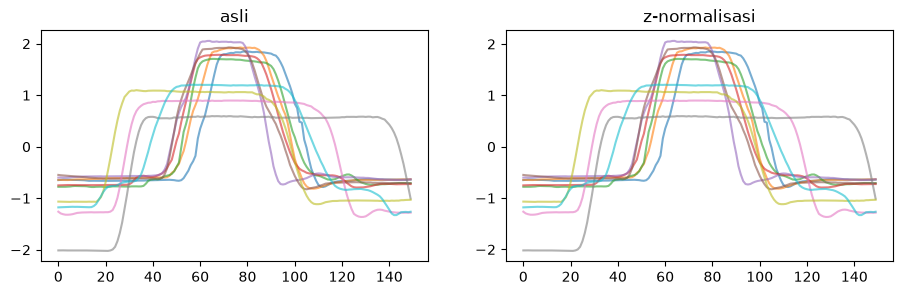

In [4]:
row_mean = X.mean(axis=1, keepdims=True)
row_std = X.std(axis=1, keepdims=True)
X_z = (X - row_mean) / row_std
X_z_3d = X_z[:, None, :]     # bentuk (deret, 1, waktu) untuk model sktime

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for i in range(10):
    axes[0].plot(X[i], alpha=0.6)
    axes[1].plot(X_z[i], alpha=0.6)
axes[0].set_title("asli")
axes[1].set_title("z-normalisasi")
plt.show()

## Fitur ringkas per deret (untuk alternatif clustering berbasis fitur)

In [5]:
features = pd.DataFrame()
features["mean"] = X.mean(axis=1)
features["std"] = X.std(axis=1)
features["max"] = X.max(axis=1)
features["max_position"] = X.argmax(axis=1)
features["min"] = X.min(axis=1)
steps = np.abs(np.diff(X, axis=1))
features["total_movement"] = steps.sum(axis=1)
features["skew"] = pd.DataFrame(X).skew(axis=1)
features_scaled = StandardScaler().fit_transform(features)
features.head()

,mean,std,max,max_position,min,total_movement,skew
0,-4.000001e-10,0.996661,1.845811,80,-0.782461,5.409111,1.051883
1,-7.400000e-10,0.996661,1.925177,77,-0.814203,5.548534,1.102117
2,-1.893333e-09,0.996661,1.703739,66,-0.782672,5.251845,0.894229
3,1.586667e-09,0.996661,1.783278,68,-0.792305,5.263265,0.978800
4,2.400000e-09,0.996661,2.053367,64,-0.733465,5.872608,1.274075


## Matriks jarak DTW (dipakai alternatif Agglomerative, ±15 detik)

In [6]:
dtw = DtwDist(window=0.1)
dtw_distance = dtw.transform(X_z_3d)
print(dtw_distance.shape)

(200, 200)


## Pilih jumlah cluster: silhouette KMeans untuk 2..6 cluster (makin tinggi makin baik)
Lalu tulis angkanya di `N_CLUSTERS` (Konfigurasi).

In [7]:
for n_clusters in range(2, 7):
    trial = KMeans(n_clusters=n_clusters, n_init=10, random_state=SEED)
    trial_labels = trial.fit_predict(X_z)
    print(n_clusters, "cluster: silhouette", round(silhouette_score(X_z, trial_labels), 3))

2 cluster: silhouette 0.435
3 cluster: silhouette 0.444


4 cluster: silhouette 0.467
5 cluster: silhouette 0.448


6 cluster: silhouette 0.369


## Model
Pilih SATU model: hapus `#` di DUA baris (model + input), beri `#` pada dua baris KMeans.

In [8]:
model = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
model_input = X_z
# model = TimeSeriesKMeans(n_clusters=N_CLUSTERS, metric="dtw", n_init=3, max_iter=20,
#                          random_state=SEED)
# model_input = X_z_3d
# model = TimeSeriesKMedoids(n_clusters=N_CLUSTERS, metric="dtw", random_state=SEED)
# model_input = X_z_3d
# model = AgglomerativeClustering(n_clusters=N_CLUSTERS, metric="precomputed",
#                                 linkage="average")
# model_input = dtw_distance
# model = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
# model_input = features_scaled
cluster_labels = model.fit_predict(model_input)

## Evaluasi: ARI terhadap label asli, silhouette, ukuran cluster, kurva rata-rata

ARI vs label asli: -0.005
silhouette (z-norm): 0.435
label     1   2
cluster        
0        50  50
1        50  50


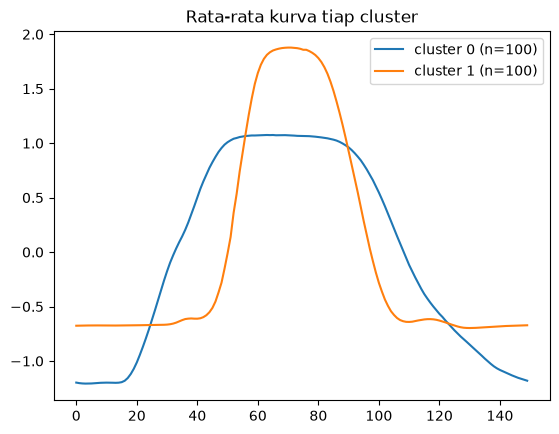

   mean  std   max  max_position   min  total_movement  skew
0  -0.0  1.0  1.10         62.15 -1.31            5.16 -0.09
1  -0.0  1.0  1.88         72.27 -0.87            5.89  1.06


In [9]:
print("ARI vs label asli:", round(adjusted_rand_score(table[LABEL_COL], cluster_labels), 3))
print("silhouette (z-norm):", round(silhouette_score(X_z, cluster_labels), 3))
print(pd.crosstab(cluster_labels, table[LABEL_COL], rownames=["cluster"]))

for cluster in np.unique(cluster_labels):
    members = X_z[cluster_labels == cluster]
    plt.plot(members.mean(axis=0), label=f"cluster {cluster} (n={len(members)})")
plt.title("Rata-rata kurva tiap cluster")
plt.legend()
plt.show()

cluster_profile = features.groupby(cluster_labels).mean()
print(cluster_profile.round(2))

## Simpan hasil (satu baris per deret)

In [10]:
result = pd.DataFrame()
result["indeks"] = table.index
result["cluster"] = cluster_labels
result.to_csv("hasil.csv", index=False)
result.head()

,indeks,cluster
0,0,1
1,1,1
2,2,1
3,3,1
4,4,1
